<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">


# Procesamiento de lenguaje natural
## Custom embedddings con Gensim



### Consigna del desafío 2

**Cada experimento realizado debe estar acompañado de una explicación o interpretación de lo observado, incluido el sustento de las decisiones que tomaron (como modificación de hiperparámetros)**

Recuerden que su notebook de entrega debe poder correrse de inicio a fin sin la aparición de errores.

- Crear sus propios vectores con Gensim basado en lo visto en clase con un corpus propio (revisar enlaces sugeridos en clase 2 sobre opciones de dataset)
- Elegir términos de interés y buscar términos más similares y menos similares.
- Realizar una reduccion de dimensionalidad a los embeddings, llevándolos a 2 dimensiones. Graficar los embeddings proyectados y seleccionar una cantidad de términos (variable MAX_WORDS) de forma tal que la visualización sea adecuada.
- Inspeccionar el grafico y buscar pequeños grupos de palabras que puedan formarse. Interpretarlos e intentar obtener conclusiones. En lo posible, acompañar los grupos de palabras con capturas (y pegarlas en celdas de texto)

In [1]:
import pandas as pd
import os
from gensim.models import Word2Vec

#### Cargar los datos

Vamos a usar las 4 novelas y 4 colecciones de cuentos de Arthur Conan Doyle protagonizadas por Sherlock Holmes

In [2]:
libros = {
    244:  "A Study in Scarlet",                # novela (1887) - primera aparición de Holmes y Watson
    2097: "The Sign of the Four",              # novela (1890)
    1661: "The Adventures of Sherlock Holmes", # cuentos (1892)
    834:  "The Memoirs of Sherlock Holmes",    # cuentos (1894)
    2852: "The Hound of the Baskervilles",     # novela (1902)
    108:  "The Return of Sherlock Holmes",     # cuentos (1905)
    3289: "The Valley of Fear",                # novela (1915)
    2350: "His Last Bow",                      # cuentos (1917)
}

Vamos a bajar los archivos en un carpeta local "corpus_sherlock".
Cada libro de Gutenberg tiene un encabezado y un pie con licencia que no son parte de la obra. El texto útil está entre las marcas *** START OF THE PROJECT GUTENBERG EBOOK y *** END OF THE PROJECT GUTENBERG EBOOK, así que nos quedamos solo con lo que hay entre ellas.

In [3]:
CARPETA = "corpus_sherlock"
os.makedirs(CARPETA, exist_ok=True)

def descargar_libro(id_libro):
    ruta = os.path.join(CARPETA, f"{id_libro}.txt")
    if not os.path.exists(ruta):
        url = f"https://www.gutenberg.org/cache/epub/{id_libro}/pg{id_libro}.txt"
        respuesta = requests.get(url, timeout=30)
        respuesta.raise_for_status()
        texto = respuesta.content.decode("utf-8-sig").replace("\r\n", "\n")
        with open(ruta, "w", encoding="utf-8", newline="\n") as f:
            f.write(texto)
    with open(ruta, encoding="utf-8") as f:
        return f.read()

def limpiar_gutenberg(texto):
    inicio = re.search(r"\*\*\* ?START OF (THE|THIS) PROJECT GUTENBERG EBOOK.*?\*\*\*", texto)
    fin = re.search(r"\*\*\* ?END OF (THE|THIS) PROJECT GUTENBERG EBOOK", texto)
    if inicio and fin:
        texto = texto[inicio.end():fin.start()]
    return texto.strip()

Vamos a descargar los 8 libros y mostrar los títulos que figuran y la cantidad de palabras de cada uno.

In [4]:
import re
import requests
textos = {}
for id_libro, nombre in libros.items():
    crudo = descargar_libro(id_libro)
    titulo = re.search(r"Title:\s*(.+)", crudo)
    textos[nombre] = limpiar_gutenberg(crudo)
    print(f"{id_libro:>5} | esperado: {nombre:<35} | en el archivo: {titulo.group(1).strip() if titulo else '¿?'}"
          f" | {len(textos[nombre].split()):>7,} palabras")

corpus_texto = "\n\n".join(textos.values())
print(f"\nTotal del corpus: {len(corpus_texto.split()):,} palabras")

  244 | esperado: A Study in Scarlet                  | en el archivo: A Study in Scarlet |  43,427 palabras
 2097 | esperado: The Sign of the Four                | en el archivo: The Sign of the Four |  43,095 palabras
 1661 | esperado: The Adventures of Sherlock Holmes   | en el archivo: The Adventures of Sherlock Holmes | 104,506 palabras
  834 | esperado: The Memoirs of Sherlock Holmes      | en el archivo: The Memoirs of Sherlock Holmes |  95,486 palabras
 2852 | esperado: The Hound of the Baskervilles       | en el archivo: The Hound of the Baskervilles |  59,260 palabras
  108 | esperado: The Return of Sherlock Holmes       | en el archivo: The Return of Sherlock Holmes | 112,116 palabras
 3289 | esperado: The Valley of Fear                  | en el archivo: The Valley of Fear |  57,814 palabras
 2350 | esperado: His Last Bow                        | en el archivo: His last bow |  59,023 palabras

Total del corpus: 574,727 palabras


Verificamos que los encabezados se hayan eliminado

In [5]:
print(textos["A Study in Scarlet"][:1000])

A STUDY IN SCARLET

By A. Conan Doyle




CONTENTS

 A STUDY IN SCARLET.

 PART I.
 CHAPTER I. MR. SHERLOCK HOLMES.
 CHAPTER II. THE SCIENCE OF DEDUCTION.
 CHAPTER III. THE LAURISTON GARDENS MYSTERY
 CHAPTER IV. WHAT JOHN RANCE HAD TO TELL.
 CHAPTER V. OUR ADVERTISEMENT BRINGS A VISITOR.
 CHAPTER VI. TOBIAS GREGSON SHOWS WHAT HE CAN DO.
 CHAPTER VII. LIGHT IN THE DARKNESS.

 PART II. THE COUNTRY OF THE SAINTS
 CHAPTER I. ON THE GREAT ALKALI PLAIN.
 CHAPTER II. THE FLOWER OF UTAH.
 CHAPTER III. JOHN FERRIER TALKS WITH THE PROPHET.
 CHAPTER IV. A FLIGHT FOR LIFE.
 CHAPTER V. THE AVENGING ANGELS.
 CHAPTER VI. A CONTINUATION OF THE REMINISCENCES OF JOHN WATSON, M.D.
 CHAPTER VII. THE CONCLUSION.




A STUDY IN SCARLET.




PART I.


(_Being a reprint from the Reminiscences of_ JOHN H. WATSON, M.D.,
_Late of the Army Medical Department._)




CHAPTER I.
MR. SHERLOCK HOLMES.


In the year 1878 I took my degree of Doctor of Medicine of the
University of London, and proceeded to Netley to go t

#### Preprocesamiento

Palabras como chapter y part, o los números romanos (i, ii, iii), se repiten decenas de veces en lugares que no son texto narrativo. Además, cada título de capítulo aparece dos veces (en el índice y en el capítulo), lo que podría generar vecinos falsos. En estos libros, algunos títulos, índices y encabezados están escritos completamente en mayúsculas, y la narración no. Entonces eliminamos las líneas que están enteras en mayúsculas.

In [6]:
def quitar_titulos(texto):
    lineas = texto.split("\n")
    conservadas = [l for l in lineas
                   if not (any(c.isalpha() for c in l) and l == l.upper())]
    return "\n".join(conservadas)

for nombre in textos:
    antes = len(textos[nombre].split())
    textos[nombre] = quitar_titulos(textos[nombre])
    print(f"{nombre:<35} {antes:>8,} → {len(textos[nombre].split()):>8,} palabras")

corpus_texto = "\n\n".join(textos.values())
print(f"\nTotal del corpus: {len(corpus_texto.split()):,} palabras")

print("\n" + textos["A Study in Scarlet"][:600])

A Study in Scarlet                    43,427 →   43,198 palabras
The Sign of the Four                  43,095 →   43,095 palabras
The Adventures of Sherlock Holmes    104,506 →  104,419 palabras
The Memoirs of Sherlock Holmes        95,486 →   95,480 palabras
The Hound of the Baskervilles         59,260 →   59,244 palabras
The Return of Sherlock Holmes        112,116 →  111,986 palabras
The Valley of Fear                    57,814 →   57,777 palabras
His Last Bow                          59,023 →   59,010 palabras

Total del corpus: 574,209 palabras


By A. Conan Doyle

















(_Being a reprint from the Reminiscences of_ JOHN H. WATSON, M.D.,
_Late of the Army Medical Department._)






In the year 1878 I took my degree of Doctor of Medicine of the
University of London, and proceeded to Netley to go through the course
prescribed for surgeons in the army. Having completed my studies there,
I was duly attached to the Fifth Northumberland Fusiliers as Assistant
Surgeon. The regi

**Limitación de la limpieza:** se eliminaron las líneas escritas completamente en mayúsculas, que corresponden a títulos, índices y encabezados de capítulos. Esto funcionó en la mayoría de los libros, pero en algunos los títulos no fueron detectados. Se decidió no hacer una limpieza manual, asumiendo que su efecto en los embeddings es mínimo. 

#### Vamos a segmentar el texto

Vamos a segmentar por oración, ya que si separamos por línea cortaríamos oraciones a la mitad.

1. Separamos cada libro en párrafos, usando las líneas en blanco.
2. Dentro de cada párrafo unimos las líneas en un solo texto.
3. Dividimos cada párrafo en oraciones con `sent_tokenize` de NLTK, que reconoce abreviaturas como *Mr.* o *Dr.* y no corta ahí.


In [7]:
import nltk
from nltk.tokenize import sent_tokenize

nltk.download("punkt")
nltk.download("punkt_tab")

def segmentar_oraciones(texto):
    parrafos = re.split(r"\n\s*\n", texto)
    oraciones = []
    for p in parrafos:
        p = " ".join(p.split())   # une las líneas del párrafo y normaliza espacios
        if p:
            oraciones.extend(sent_tokenize(p))
    return oraciones

oraciones = []
for nombre, texto in textos.items():
    oraciones_libro = segmentar_oraciones(texto)
    oraciones.extend(oraciones_libro)
    print(f"{nombre:<35} {len(oraciones_libro):>6,} oraciones")

print(f"\nTotal: {len(oraciones):,} oraciones")
print("\nEjemplos:")
for o in oraciones[3:8]:
    print("-", o)

[nltk_data] Downloading package punkt to C:\Users\Gonzalo
[nltk_data]     Rodriguez\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to C:\Users\Gonzalo
[nltk_data]     Rodriguez\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


A Study in Scarlet                   2,578 oraciones
The Sign of the Four                 2,827 oraciones
The Adventures of Sherlock Holmes    6,520 oraciones
The Memoirs of Sherlock Holmes       5,762 oraciones
The Hound of the Baskervilles        3,821 oraciones
The Return of Sherlock Holmes        7,605 oraciones
The Valley of Fear                   4,121 oraciones
His Last Bow                         4,436 oraciones

Total: 37,670 oraciones

Ejemplos:
- Having completed my studies there, I was duly attached to the Fifth Northumberland Fusiliers as Assistant Surgeon.
- The regiment was stationed in India at the time, and before I could join it, the second Afghan war had broken out.
- On landing at Bombay, I learned that my corps had advanced through the passes, and was already deep in the enemy’s country.
- I followed, however, with many other officers who were in the same situation as myself, and succeeded in reaching Candahar in safety, where I found my regiment, and at once enter

#### Tokenización de palabras

Vamos a convertir palabras a minúsculas, sin signos de puntuación. Comillas y apóstrofos tipográficos (“ ” ‘ ’): se convierten a los comunes, para que no queden pegados a las palabras. Apóstrofos sueltos al inicio o al final de una palabra se quitan, pero se conservan los internos.

In [8]:
FILTROS = '!"#$%&()*+,-./:;<=>?@[\\]^_`{|}~\t\n'
TABLA = str.maketrans(FILTROS, " " * len(FILTROS))

def tokenizar(oracion):
    oracion = (oracion.replace("’", "'").replace("‘", "'")
                      .replace("“", '"').replace("”", '"'))
    palabras = oracion.lower().translate(TABLA).split()
    palabras = [p.strip("'") for p in palabras if p.strip("'")]
    return [p[:-2] if p.endswith("'s") else p for p in palabras]   # holmes's → holmes

documentos = [tokenizar(o) for o in oraciones]
documentos = [d for d in documentos if d]     # descartamos oraciones vacías

vocabulario = {p for d in documentos for p in d}
print(f"Documentos (oraciones): {len(documentos):,}")
print(f"Largo promedio: {sum(len(d) for d in documentos) / len(documentos):.1f} palabras")
print(f"Vocabulario (palabras distintas): {len(vocabulario):,}")
print("\nEjemplo:", documentos[5])

Documentos (oraciones): 37,667
Largo promedio: 15.3 palabras
Vocabulario (palabras distintas): 19,377

Ejemplo: ['on', 'landing', 'at', 'bombay', 'i', 'learned', 'that', 'my', 'corps', 'had', 'advanced', 'through', 'the', 'passes', 'and', 'was', 'already', 'deep', 'in', 'the', 'enemy', 'country']


Se eliminó el `'s` de los posesivos para que, por ejemplo, *holmes's* y *holmes* se consideren la misma palabra. Esto redujo el vocabulario de 19.792 a 19.377 palabras distintas y concentra más ejemplos de entrenamiento en cada término, algo importante en este corpus, donde expresiones como *Holmes's room* son muy frecuentes.

#### Creamos los vectores (word2vec)

In [9]:
from gensim.models import Word2Vec
from gensim.models.callbacks import CallbackAny2Vec

# Durante el entrenamiento gensim por defecto no informa el "loss" en cada época
# Sobrecargamos el callback para poder tener esta información
class callback(CallbackAny2Vec):
    """
    Callback to print loss after each epoch
    """
    def __init__(self):
        self.epoch = 0

    def on_epoch_end(self, model):
        loss = model.get_latest_training_loss()
        if self.epoch == 0:
            print('Loss after epoch {}: {}'.format(self.epoch, loss))
        else:
            print('Loss after epoch {}: {}'.format(self.epoch, loss - self.loss_previous_step))
        self.epoch += 1
        self.loss_previous_step = loss

**Hiperparámetros del modelo**

Partimos del tamaño de nuestro corpus (37.667 oraciones, unas 574.000 palabras). La selección de los 2 hiperparámetros más significativos, window y vector_size, se toma inicialmente por el largo de las oraciones (window) y por la cantidad de palabras (vector_size). Más adelante se prueban distintos valores y se justifican.
| Parámetro | Nuestro valor | Justificación |
|---|---|---|
| `min_count` | 5 | Las palabras que aparecen menos de 5 veces (typos, nombres de un solo cuento) no tienen contexto suficiente para aprender un vector confiable. |
| `window` | 5 | Las oraciones tienen en promedio 15,3 palabras. Una ventana de 5 palabras a cada lado cubre buena parte de la oración sin mezclar ideas lejanas. |
| `vector_size` | 100 | El vocabulario final es de 6.382 palabras. 100 dimensiones es un valor estándar para un corpus mediano; más dimensiones necesitarían más texto para aprovecharse. |
| `negative` | 10 | Al tener más texto hay más ejemplos de entrenamiento, por lo que no hace falta tomar tantos ejemplos negativos por cada par. |
| `sg` | 1 (Skip-gram) | Según lo visto, Skip-gram aprovecha mejor un corpus mediano y aprende mejor las palabras poco frecuentes, como los personajes secundarios. Es más lento que CBOW, pero el tamaño del corpus lo permite. |
| `workers` | 1 | Solo afecta la velocidad de entrenamiento (cantidad de núcleos de la CPU). |
| `epochs` | 20 | Se mantiene el valor bajo y se verifica con la pérdida que el modelo aprende. |
| `seed` | 42 | Fija la aleatoriedad del entrenamiento para que los resultados sean reproducibles. |

In [10]:
# Creamos el modelo generador de vectores
# En este caso utilizaremos la estructura modelo Skipgram

w2v_model = Word2Vec(
    min_count=5,       # frecuencia mínima para entrar al vocabulario
    window=5,          # ventana de contexto
    vector_size=100,   # dimensión de los embeddings
    negative=10,       # ejemplos negativos por par
    sg=1,              # 1 = Skip-gram, 0 = CBOW
    workers=1,
    seed=42            # valor de semilla para reproducibilidad
)

In [11]:
w2v_model.build_vocab(documentos)
print(f"Vocabulario del modelo: {len(w2v_model.wv.index_to_key):,} palabras "
      f"(de {len(vocabulario):,} distintas en el corpus)")

Vocabulario del modelo: 6,382 palabras (de 19,377 distintas en el corpus)


In [12]:
total_tokens = sum(len(d) for d in documentos)
tokens_cubiertos = sum(1 for d in documentos for p in d if p in w2v_model.wv.key_to_index)
print(f"Las {len(w2v_model.wv.index_to_key):,} palabras del modelo cubren el "
      f"{tokens_cubiertos / total_tokens:.1%} del texto")

Las 6,382 palabras del modelo cubren el 96.2% del texto


Con `min_count=5`, el modelo conserva 6.382 de las 19.377 palabras distintas del corpus: se descarta aproximadamente el 67% del vocabulario. Sin embargo, esas 6.382 palabras cubren el 96,2% del texto, porque las palabras descartadas aparecen muy pocas veces cada una (typos, nombres de un solo cuento, términos poco comunes). Se eliminan muchas palabras raras, sobre las que el modelo no tendría contexto suficiente para aprender un vector confiable, perdiendo solo el 3,8% del contenido.

#### Entrenar los embeddings

In [13]:
w2v_model.train(documentos,
                total_examples=w2v_model.corpus_count,
                epochs=20,
                compute_loss=True,
                callbacks=[callback()])

Loss after epoch 0: 5549583.5
Loss after epoch 1: 4238647.5
Loss after epoch 2: 3999200.0
Loss after epoch 3: 3920787.0
Loss after epoch 4: 3748132.0
Loss after epoch 5: 3736920.0
Loss after epoch 6: 3708760.0
Loss after epoch 7: 3700182.0
Loss after epoch 8: 3699152.0
Loss after epoch 9: 3677908.0
Loss after epoch 10: 3663752.0
Loss after epoch 11: 3634144.0
Loss after epoch 12: 3612812.0
Loss after epoch 13: 3613976.0
Loss after epoch 14: 3605976.0
Loss after epoch 15: 3604400.0
Loss after epoch 16: 3603668.0
Loss after epoch 17: 1867688.0
Loss after epoch 18: 152024.0
Loss after epoch 19: 150400.0


(7775286, 11562480)

La pérdida baja de 5.549.583 en la primera época a unos 3.750.000 en la época 4, lo que muestra que la mayor parte del aprendizaje ocurre en las primeras épocas. Después la mejora es muy lenta: entre las épocas 10 y 16 baja menos del 1% por época (de 3.663.752 a 3.603.668), es decir, el modelo se estabiliza.

A partir de la época 17 la pérdida cae bruscamente (1.867.688 y luego unos 150.000). Esta caída no es una mejora real del modelo, sino un error numérico conocido de Gensim: la pérdida se guarda como un total acumulado de todas las épocas en un número de precisión limitada (`float32`), y cuando ese total se vuelve muy grande deja de registrar correctamente los nuevos valores, por lo que la diferencia entre épocas da valores artificialmente bajos.

Por eso la pérdida se usa solo para verificar que el modelo aprende en las primeras épocas, y la evaluación real de los embeddings se hace analizando las palabras más y menos similares.

### Selección de hiperparámetros del modelo

Como se dijo en la conclusión anterior, la mejor forma de evaluar el desempeño de los hiperparámetros es analizando la similitud de palabras. 
Elegimos tres palabras que representan conceptos centrales de las historias de detectives: *murder* (el crimen), *police* (la investigación) y *money* (uno de los móviles más comunes). Para cada una mostramos las 6 palabras más similares, junto con la similitud coseno y la cantidad de veces que aparece cada palabra en el corpus.

También probamos con nombres propios como *holmes*, pero sus vecinos fueron otros personajes y adverbios que acompañan al diálogo. Esto muestra que el modelo agrupa los nombres por su rol en la oración más que por su significado, y por eso preferimos analizar palabras de concepto.

Como dijimos arriba, los parámetros que a nuestro criterio son más significativos son window y vector_size, así que entrenamos el modelo con distintos valores y vemos que valores de similitud obtenemos en las palabras definidas.

Primero analizamos distintos valores de vector_size

In [14]:
for dim in [100, 300, 1000]:
    modelo = Word2Vec(documentos, min_count=5, window=5, vector_size=dim,
                      negative=10, sg=1, workers=1, epochs=20, seed=42)
    print(f"\n===== vector_size = {dim} =====")
    for palabra in ["murder", "police", "money"]:
        vecinos = [w for w, _ in modelo.wv.most_similar(palabra, topn=6)]
        print(f"{palabra:<8} → {vecinos}")


===== vector_size = 100 =====
murder   → ['crime', 'suicide', 'arrest', 'murdering', 'supernatural', 'attempted']
police   → ['official', 'lascar', 'constabulary', 'magistrates', 'manager', 'secretly']
money    → ['price', 'imprisonment', 'title', 'audacity', 'wealth', 'enable']

===== vector_size = 300 =====
murder   → ['crime', 'murdering', 'suicide', 'deliberate', 'conspiracy', 'vat']
police   → ['magistrates', 'constabulary', 'detectives', 'lascar', "we're", 'manager']
money    → ['securities', 'jewels', 'sum', 'price', 'imprisonment', 'services']

===== vector_size = 1000 =====
murder   → ['murdering', 'suicide', 'crime', 'deliberate', 'conspiracy', 'attempted']
police   → ['magistrates', 'constabulary', 'lascar', "we're", 'detectives', 'secretly']
money    → ['securities', 'sum', 'jewels', 'price', 'imprisonment', 'services']


**Comparación de `vector_size` (100, 300 y 1.000)**

- **Hay un núcleo de vecinos que se mantiene en las tres dimensiones:** *crime, suicide, murdering* para *murder*; *magistrates, constabulary, lascar* para *police*; *price, imprisonment* para *money*. Son las relaciones que el modelo aprende con más fuerza, independientemente de la dimensión.
- **Con 300 los resultados mejoran respecto de 100:** hay menos vecinos sin relación clara, y en particular *money* pasa de incluir palabras poco relacionadas (*audacity, enable*) a vecinos coherentes con el dinero (*securities, jewels, sum, services*). *Police* también suma *detectives*.
- **300 y 1.000 dan prácticamente el mismo resultado:** en *money* los seis vecinos son los mismos, y en *murder* y *police* coinciden cinco de seis. Pasar a 1.000 dimensiones multiplica por más de tres la cantidad de parámetros sin mejorar los resultados, lo que indica que el corpus no tiene información suficiente para aprovechar tantas dimensiones.

Por lo tanto, se eligió `vector_size=300`: mejora la calidad de los vecinos respecto de 100, y a partir de ese valor agregar dimensiones no aporta. Como limitación, la comparación es cualitativa y se basa en tres palabras.

In [15]:
for ventana in [2, 5, 10]:
    modelo = Word2Vec(documentos, min_count=5, window=ventana, vector_size=300,
                      negative=10, sg=1, workers=1, seed=42, epochs=20)
    print(f"\n===== window = {ventana} =====")
    for palabra in ["murder", "police", "money"]:
        vecinos = [w for w, _ in modelo.wv.most_similar(palabra, topn=6)]
        print(f"{palabra:<8} → {vecinos}")


===== window = 2 =====
murder   → ['sender', 'suicide', 'crime', 'robbery', 'murdering', 'burglary']
police   → ['railroad', 'sender', 'killing', 'magistrates', 'langham', 'euston']
money    → ['food', 'barrymores', 'deserts', 'machine', 'audacity', 'billet']

===== window = 5 =====
murder   → ['crime', 'murdering', 'suicide', 'deliberate', 'conspiracy', 'vat']
police   → ['magistrates', 'constabulary', 'detectives', 'lascar', "we're", 'manager']
money    → ['securities', 'jewels', 'sum', 'price', 'imprisonment', 'services']

===== window = 10 =====
murder   → ['conspiracy', 'arrest', 'suicide', 'crime', 'vat', 'deliberate']
police   → ['constabulary', 'authorities', 'prompt', 'headquarters', 'detectives', 'foreigners']
money    → ['securities', 'sum', 'sums', 'jewels', 'price', 'estate']


**Comparación de `window` (2, 5 y 10), con `vector_size=300`**

- **Con ventana 2 los resultados son ruidosos:** el modelo solo ve las palabras inmediatamente cercanas, lo que alcanza para agrupar palabras intercambiables en *murder* (*robbery, burglary, suicide*), pero no para *police* (*railroad, langham, euston*) ni para *money* (*food, deserts, machine*), que aparecen en contextos más variados.
- **Con ventana 5 los resultados son coherentes**, aunque con algunos vecinos sin relación clara (*vat, we're, manager*).
- **Con ventana 10 se obtienen los vecinos más coherentes:** *police* queda asociada a la institución policial (*constabulary, authorities, headquarters, detectives*) y los seis vecinos de *money* están relacionados con el dinero (*securities, sum, sums, jewels, price, estate*). En *murder* aparece *arrest* y desaparece *murdering*: con una ventana más grande el modelo captura más relaciones de **tema** que de posición en la oración.

Como las oraciones del corpus tienen en promedio 15,3 palabras, una ventana de 10 permite aprovechar casi todo el contexto de cada oración. Se eligió `window=10`.

#### Modelo final

A partir de los experimentos anteriores entrenamos el modelo final con `vector_size=300` y `window=10`, manteniendo el resto de los parámetros. Este es el modelo que se usa en todo el análisis siguiente.

In [16]:
w2v_model = Word2Vec(
    documentos,
    min_count=5,       # frecuencia mínima para entrar al vocabulario
    window=10,         # elegido en el experimento de window
    vector_size=300,   # elegido en el experimento de vector_size
    negative=10,       # ejemplos negativos por par
    sg=1,              # Skip-gram
    workers=1,
    seed=42,           # semilla para reproducibilidad
    epochs=20,
)
print(f"Vocabulario del modelo final: {len(w2v_model.wv.index_to_key):,} palabras")

Vocabulario del modelo final: 6,382 palabras


### Ensayar

##### Vamos a definir una función para buscar las palabras más similares.

In [17]:
import pandas as pd

def palabras_similares(palabra, n=10):
    if palabra not in w2v_model.wv.key_to_index:
        print(f"'{palabra}' no está en el vocabulario del modelo")
        return
    print(f"Palabra: '{palabra}'  |  aparece {w2v_model.wv.get_vecattr(palabra, 'count')} veces")
    similares = w2v_model.wv.most_similar(positive=[palabra], topn=n)
    tabla = pd.DataFrame({
        "palabra similar": [p for p, _ in similares],
        "similitud": [round(s, 3) for _, s in similares],
        "frecuencia": [w2v_model.wv.get_vecattr(p, "count") for p, _ in similares],
    })
    display(tabla.style.hide(axis="index"))

In [18]:
palabras_similares("murder")

Palabra: 'murder'  |  aparece 146 veces


palabra similar,similitud,frecuencia
conspiracy,0.457000,11
arrest,0.452000,53
suicide,0.449000,18
crime,0.448000,202
vat,0.442000,5
deliberate,0.442000,8
guilt,0.438000,18
murdering,0.432000,6
attempted,0.426000,15
verdict,0.421000,7


**Análisis de *murder*:** los vecinos forman un campo semántico coherente alrededor del crimen y su investigación:
- *crime* es el concepto general del que el asesinato es un caso particular, y es el vecino más frecuente.
- *murdering* es otra forma de la misma palabra: como no lematizamos, tiene su propio vector, pero el modelo aprendió que están relacionadas.
- *suicide* es la explicación alternativa de una muerte. En las historias de detectives la pregunta "¿fue asesinato o suicidio?" es habitual.
- *arrest*, *guilt* y *verdict* corresponden al proceso legal que sigue al crimen: el arresto, la culpabilidad y el veredicto.
- *conspiracy* es otro delito que suele aparecer junto al asesinato en las acusaciones.
- *attempted* y *deliberate* aparecen en expresiones como *"attempted murder"* o *"deliberate murder"*.

Los vecinos menos confiables son los poco frecuentes: *vat* (5 apariciones), *murdering* (6), *verdict* (7) y *deliberate* (8), que apenas superan el `min_count=5` y cuyo vector depende de muy pocas oraciones. En particular, *vat* no tiene una relación clara con *murder*.

In [19]:
palabras_similares("police")

Palabra: 'police'  |  aparece 283 veces


palabra similar,similitud,frecuencia
constabulary,0.396000,8
authorities,0.374000,12
prompt,0.371000,13
headquarters,0.369000,8
detectives,0.365000,25
foreigners,0.363000,5
forbes,0.358000,9
constable,0.356000,40
officer,0.355000,27
magistrates,0.351000,5


**Análisis de *police*:** los vecinos se agrupan en tres ideas relacionadas con la institución policial:
- **Personas y autoridades:** *detectives*, *constable* (el agente de uniforme), *officer*, *magistrates* (los jueces) y *authorities*. En los cuentos Holmes trabaja constantemente con la policía.
- **Lugares e institución:** *constabulary* (otra forma de nombrar a la policía) y *headquarters*, en expresiones como *"police headquarters"*.
- **Proceso:** *prompt*, en expresiones como *"prompt action of the police"*.

*forbes* probablemente corresponde a Forbes, un detective de Scotland Yard que aparece en uno de los cuentos, por lo que su relación con *police* tiene sentido aunque aparezca solo 9 veces. En cambio, *foreigners* (5 apariciones) no tiene una relación clara y probablemente se deba a una coincidencia en pocas oraciones.

Nuevamente, los vecinos más frecuentes (*constable* 40, *officer* 27, *detectives* 25) son los más coherentes.

In [20]:
palabras_similares("money")

Palabra: 'money'  |  aparece 157 veces


palabra similar,similitud,frecuencia
securities,0.481000,15
sum,0.448000,41
sums,0.446000,10
jewels,0.433000,18
price,0.415000,34
estate,0.413000,26
restore,0.413000,6
profit,0.408000,9
debt,0.402000,13
buy,0.399000,15


**Análisis de *money*:** los vecinos se agrupan en tres ideas:
- **Cantidad y valor:** *sum*, *sums* y *price*.
- **Riqueza y patrimonio:** *securities* (títulos o valores financieros), *estate* (propiedades o herencia) y *jewels*. Por ejemplo, el heredero recibe la propiedad de la familia, y esa herencia puede ser el móvil de un crimen.
- **Transacciones:** *buy*, *profit* y *debt*: comprar, ganar y deber dinero.

*restore* (6 apariciones) podría venir de expresiones como *"restore the money"* o *"restore the jewels"*.

Este resultado muestra que **el corpus influye en el significado**: además de las palabras generales sobre dinero (*sum*, *price*, *buy*), aparecen términos ligados al contexto de estos libros, como *jewels*, *securities* y *estate*, que vinculan el dinero con los robos y las herencias que se investigan en los relatos.

##### Definimos una función para buscar las palabras menos similares

In [21]:
def palabras_menos_similares(palabra, n=10):
    if palabra not in w2v_model.wv.key_to_index:
        print(f"'{palabra}' no está en el vocabulario del modelo")
        return
    print(f"Palabra: '{palabra}'  |  aparece {w2v_model.wv.get_vecattr(palabra, 'count')} veces")
    opuestas = w2v_model.wv.most_similar(negative=[palabra], topn=n)
    tabla = pd.DataFrame({
        "palabra menos similar": [p for p, _ in opuestas],
        "similitud con el opuesto": [round(s, 3) for _, s in opuestas],
        "similitud real": [round(w2v_model.wv.similarity(palabra, p), 3) for p, _ in opuestas],
        "frecuencia": [w2v_model.wv.get_vecattr(p, "count") for p, _ in opuestas],
    })
    display(tabla.style.hide(axis="index"))

In [22]:
palabras_menos_similares("murder")

Palabra: 'murder'  |  aparece 146 veces


palabra menos similar,similitud con el opuesto,similitud real,frecuencia
quarters,0.075000,-0.075000,32
dressed,0.074000,-0.074000,78
high,0.074000,-0.074000,170
frock,0.066000,-0.066000,17
chemical,0.062000,-0.062000,21
draw,0.056000,-0.056000,53
smoked,0.051000,-0.051000,23
cut,0.049000,-0.049000,128
gown,0.048000,-0.048000,39
suit,0.046000,-0.046000,42


In [23]:
palabras_menos_similares("police")

Palabra: 'police'  |  aparece 283 veces


palabra menos similar,similitud con el opuesto,similitud real,frecuencia
faced,0.041000,-0.041000,69
heavily,0.040000,-0.040000,43
fashioned,0.039000,-0.039000,21
elderly,0.028000,-0.028000,39
easily,0.028000,-0.028000,55
rugged,0.027000,-0.027000,7
o,0.027000,-0.027000,32
iron,0.024000,-0.024000,64
shawl,0.024000,-0.024000,8
fifty,0.023000,-0.023000,51


In [24]:
palabras_menos_similares("money")

Palabra: 'money'  |  aparece 157 veces


palabra menos similar,similitud con el opuesto,similitud real,frecuencia
later,0.116000,-0.116000,145
coming,0.094000,-0.094000,169
gloom,0.083000,-0.083000,34
yell,0.078000,-0.078000,8
footsteps,0.062000,-0.062000,25
opposite,0.059000,-0.059000,52
dim,0.058000,-0.058000,24
paused,0.056000,-0.056000,14
flying,0.055000,-0.055000,19
pointed,0.055000,-0.055000,62


**Análisis de las palabras menos similares**

En los tres casos la "similitud real" (coseno directo entre las palabras) está entre −0,02 y −0,12, es decir, prácticamente en cero. Estas palabras **no son opuestas** a las analizadas sino **ortogonales**: no comparten contextos.

Además, no son palabras raras (la mayoría aparece entre 20 y 170 veces), sino palabras bien aprendidas que pertenecen a otro tipo de texto:
- ***murder***: *dressed, frock, gown, suit* y *smoked, chemical*. Son palabras de las partes **descriptivas** de los relatos: la ropa de los personajes y las escenas cotidianas. En esos pasajes no se habla del crimen.
- ***police***: *elderly, rugged, faced, fashioned, shawl*. Son palabras de la **descripción física** de los personajes (su edad, su aspecto y su ropa), que nunca aparecen junto a la policía. *faced* y *fashioned* vienen de palabras compuestas como *"red-faced"* u *"old-fashioned"*.
- ***money***: *gloom, dim, footsteps, yell, paused, coming, flying*. Son palabras de **ambientación y movimiento** (*"in the gloom"*, *"a dim light"*, *"the sound of footsteps"*), propias de las escenas de suspenso.

El modelo separó el vocabulario del **crimen y la investigación** del vocabulario de la **ambientación y la descripción**, que son las dos grandes partes de la narración.

#### Visualizar agrupación de vectores

Reducimos los embeddings de 300 dimensiones a 2 con t-SNE. Como vimos en clase, es una técnica no lineal: preserva mejor qué palabras son vecinas que PCA, que es lineal. Se aplica a todo el vocabulario del modelo, y después elegimos qué palabras graficar.

In [25]:
from sklearn.manifold import TSNE
import numpy as np

def reduce_dimensions(model, num_dimensions=2):
    vectors = np.asarray(model.wv.vectors)
    labels = np.asarray(model.wv.index_to_key)
    tsne = TSNE(n_components=num_dimensions, random_state=0)
    vectors = tsne.fit_transform(vectors)
    return vectors, labels

vecs, labels = reduce_dimensions(w2v_model)
print(vecs.shape)   # (palabras del vocabulario, 2)

(6382, 2)


Para graficar elegimos `MAX_WORDS = 350`. Como el vocabulario está ordenado por frecuencia, las primeras palabras son stopwords (*the, of, and...*), que no forman grupos interesantes, por lo que las filtramos y graficamos las 350 palabras de contenido más frecuentes. Con 200 palabras se formaban pocos grupos y con 1.000 las etiquetas se superponían demasiado; 350 fue un buen equilibrio entre cantidad de palabras y legibilidad.

In [26]:
import plotly.express as px
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

MAX_WORDS = 350

# Índices de las palabras que no son stopwords, en orden de frecuencia
indices = [i for i, w in enumerate(labels) if w not in ENGLISH_STOP_WORDS][:MAX_WORDS]

fig = px.scatter(x=vecs[indices, 0], y=vecs[indices, 1], text=labels[indices])
fig.update_traces(textposition="top center", marker=dict(size=4), textfont=dict(size=10))
fig.update_layout(width=1100, height=800, title=f"Embeddings en 2D (t-SNE) – {MAX_WORDS} palabras más frecuentes sin stopwords")
fig.show()

**Grupo: el caso y su relato**

Palabras: *case, affair, singular, occurred, happened, account, story, evidence, crime*.

Este grupo reúne el vocabulario con el que se habla de los casos que investiga Holmes:
- ***case* y *affair*** son sinónimos en estos libros: Holmes llama indistintamente "case" o "affair" a cada investigación. Cerca aparece ***singular***, porque es el adjetivo que más usa para describirlos (*"a most singular case"*, *"this singular affair"*).
- ***occurred* y *happened*** son los dos puntos más cercanos del grupo: son verbos sinónimos que aparecen en las mismas frases (*"what happened"* / *"what occurred"*).
- ***account* y *story*** corresponden al relato de los hechos: en casi todos los cuentos un cliente le cuenta su historia a Holmes (*"give me an account of..."*, *"tell me your story"*).

El modelo agrupó palabras que no son sinónimos entre sí, pero que aparecen en los mismos momentos de la narración: cuando se presenta y se relata un caso.

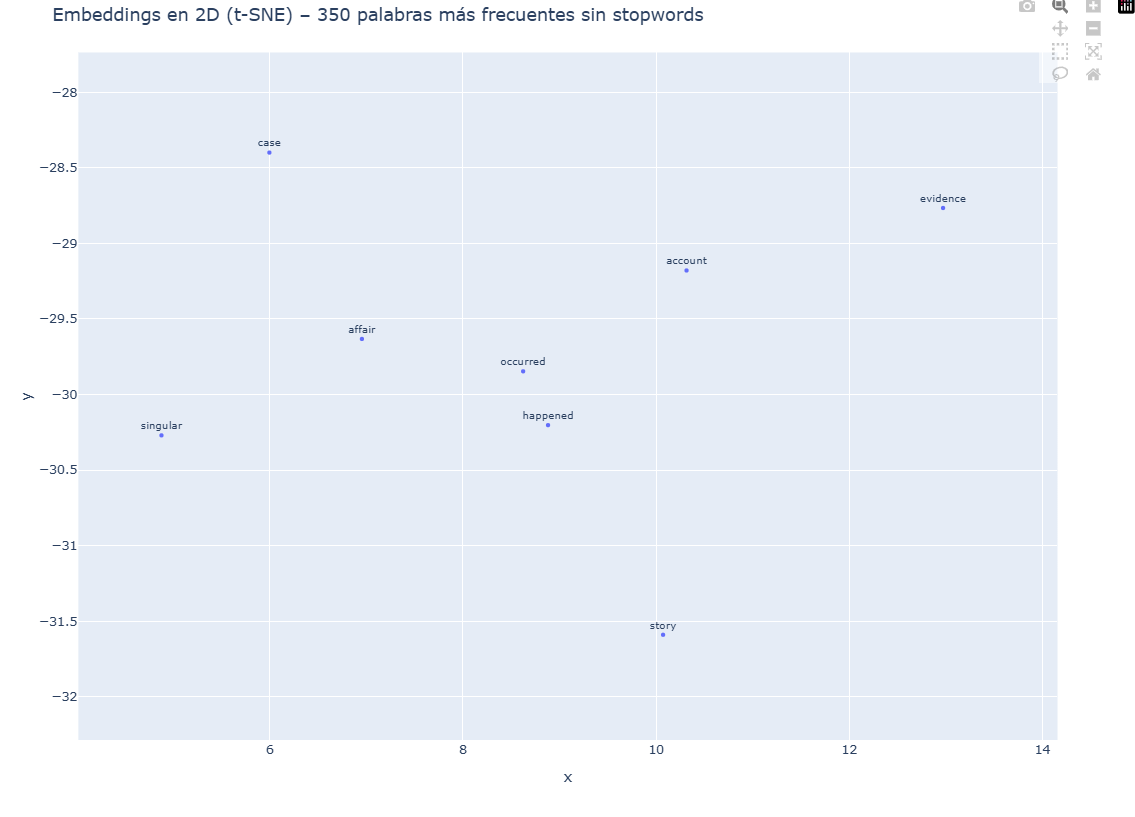

**Grupo: las acciones de la narración**

Palabras: *pocket, paper, note, read, laid, drew, examined* y *saw, heard, took, went, fell, entered, step, passed, left, observed, began, room*.

Este grupo reúne los verbos en pasado con los que se narran las acciones de los personajes, y se divide en dos partes:
- **A la izquierda, el manejo de pistas y documentos:** *pocket, paper, note, read, laid, drew, examined*. Corresponden a una escena muy repetida en los relatos: un personaje saca un papel del bolsillo, lo deja sobre la mesa y Holmes lo lee y lo examina (*"he drew a paper from his pocket"*, *"he laid it on the table"*, *"Holmes read the note"*).
- **A la derecha, las acciones generales de la narración:** *saw, heard, took, went, entered, left, passed, fell, began*. Son los verbos con los que el narrador cuenta lo que pasa (*"I heard a step"*, *"he entered the room"*, *"we went out"*). *step* y *room* aparecen cerca porque acompañan a estos verbos en frases como *"a step on the stair"* o *"entered the room"*.

En el medio, *examined* y *observed* conectan las dos partes: son acciones de la narración, pero vinculadas a la observación de pistas, que es el método de Holmes.

El modelo agrupó estas palabras porque cumplen la misma función en la oración (verbos de acción en pasado) y aparecen en el mismo tipo de escenas narrativas.

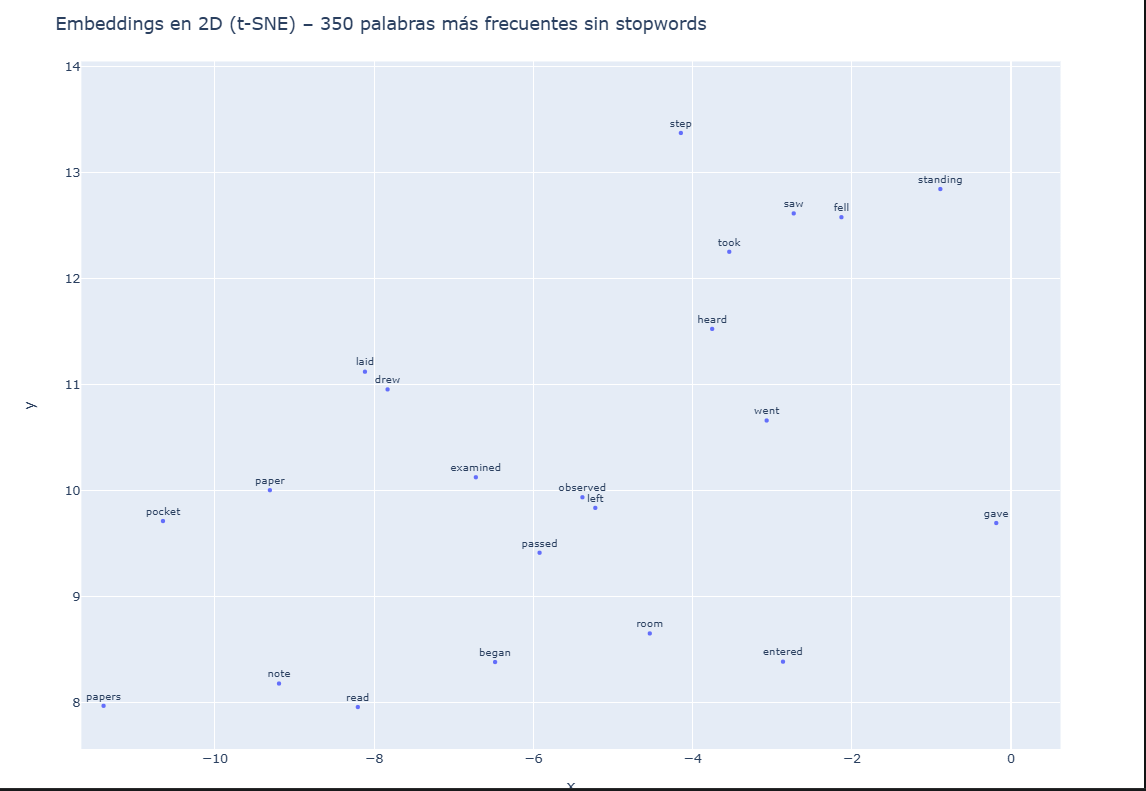

**Grupo: viajes, horarios y Baker Street**

Palabras: *train, station, cab, horse, reached, home, hour, past, o'clock, baker, street*.

Este grupo reúne el vocabulario de los traslados de los personajes, una parte muy repetida de los relatos:
- **Medios de transporte y destinos:** *train, station, cab, horse, reached, home*. En casi todos los casos Holmes y Watson viajan para investigar: toman un tren, llegan a una estación, se trasladan en un carruaje de alquiler (*cab*) o vuelven a casa (*"we reached the station"*, *"we took a cab"*, *"we drove home"*).
- **Horarios:** *hour, past, o'clock*, en frases como *"half past ten"* o *"at eleven o'clock"*. Aparecen cerca del transporte porque los viajes se narran con horarios precisos (*"the train leaves at ... o'clock"*).
- ***baker* y *street***: aparecen superpuestas, porque casi siempre aparecen juntas en *"Baker Street"*, la calle donde viven Holmes y Watson. Es un ejemplo de cómo el modelo trata como casi idénticas a dos palabras que forman una expresión fija, ya que comparten exactamente los mismos contextos.

El modelo agrupó palabras de categorías distintas (transporte, tiempo y lugares) porque aparecen en el mismo tipo de escena: los viajes y traslados de la investigación.

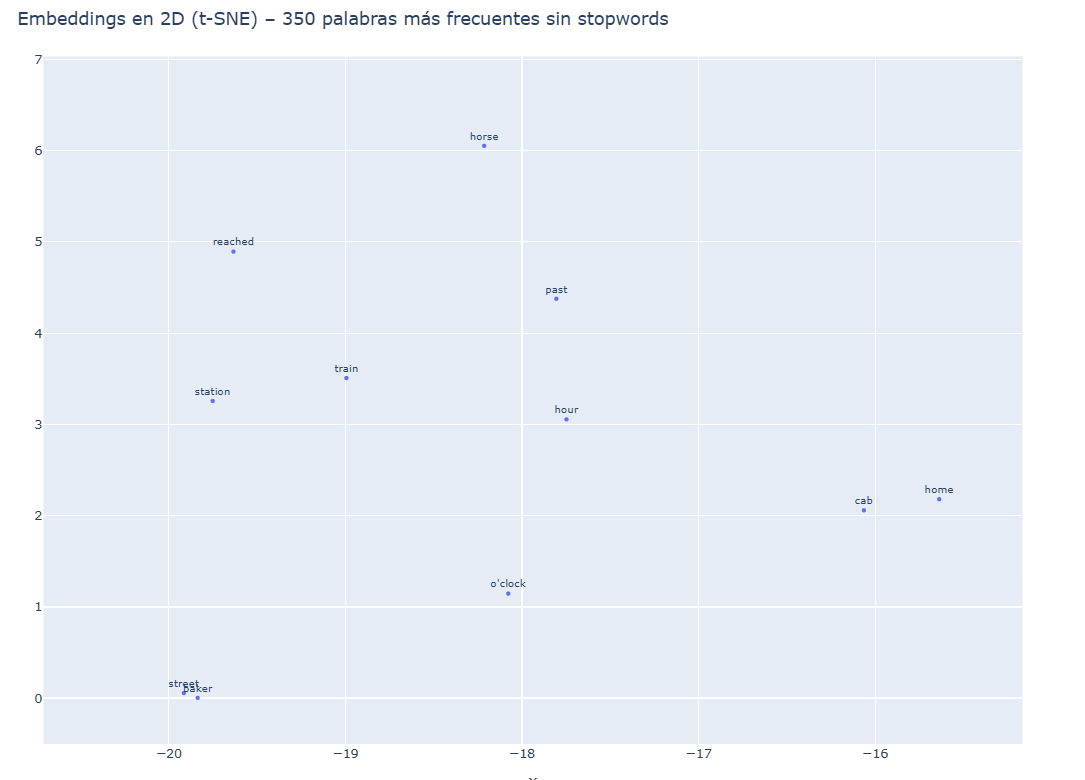

### Conclusiones

- Se entrenaron embeddings Word2Vec (Skip-gram) sobre 8 libros de Sherlock Holmes (unas 574.000 palabras). El tamaño del corpus permitió obtener relaciones muy coherentes.
- **Selección de hiperparámetros:** comparando los vecinos de *murder, police* y *money* se eligió `vector_size=300`, porque mejora los resultados respecto de 100, mientras que 1.000 no aporta cambios. También se eligió `window=10`: una ventana de 2 da resultados ruidosos, y con 10 el modelo aprovecha casi toda la oración (15,3 palabras en promedio) y captura mejor las relaciones de tema.
- **Las palabras de concepto forman campos semánticos coherentes:** *murder* se asocia al crimen y al proceso legal (*crime, arrest, guilt, verdict*), *police* a la institución policial (*constable, officer, detectives, headquarters*) y *money* a cantidades, patrimonio y transacciones (*sum, securities, estate, buy*). Esto se explica por la hipótesis distribucional vista en clase: una palabra se define por los contextos en los que aparece.
- **El corpus influye en el significado:** *money* quedó asociado a *jewels, securities* y *estate*, porque en estos libros el dinero aparece ligado a robos y herencias.
- **La frecuencia importa:** los vecinos frecuentes son coherentes, y los que apenas superan el `min_count` (*vat, foreigners, restore*) dependen de pocas oraciones y suelen ser casuales.
- **Las palabras menos similares no son antónimos:** su similitud es cercana a cero y corresponden a palabras de otros contextos (descripción física y ambientación). El modelo separa el vocabulario del crimen y la investigación del vocabulario descriptivo.
- **En la proyección 2D los grupos se forman por escenas de la narración más que por sinónimos:** la presentación de un caso (*case, affair, account, story*), las acciones narradas (*drew, examined, entered, heard*) y los viajes (*train, station, cab, o'clock*). Las expresiones fijas, como *Baker Street*, quedan prácticamente superpuestas porque sus palabras comparten exactamente los mismos contextos.